<a href="https://colab.research.google.com/github/giovanardo/DATA201-labs/blob/main/Assignments/Week8_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Finding the Right Amount of Regularization

## Week 8 Assingment

Investigate how the strength of regularization affects model performance, complexity, and
interpretability.

## Part 1 - Experiment with α

Using the same training and test sets from the lab, fit three Lasso models with:
alpha_values = [0.1, 10, 100]

For each model, report:
* Training RMSE
* Test RMSE
* Number of nonzero coefficients

Create a table comparing the three models.

In [1]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
hitters = load_data('Hitters')
print('Original shape:', hitters.shape)
display(hitters.head())
print('Missing values:')
print(hitters.isna().sum().sort_values())

Original shape: (322, 20)


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


Missing values:
AtBat         0
Hits          0
HmRun         0
Runs          0
RBI           0
Walks         0
Years         0
CAtBat        0
CHits         0
CHmRun        0
CRuns         0
CRBI          0
CWalks        0
League        0
Division      0
PutOuts       0
Assists       0
Errors        0
NewLeague     0
Salary       59
dtype: int64


In [4]:
#remove the missing information
hitters = hitters.dropna(subset=['Salary']).copy()

#Set your features and target
X = hitters.drop(columns='Salary')
y = hitters['Salary']    # thousands of dollars

#define num/cat for later scaling and encoding
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print(category_cols)

#split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

#you can check how many rows went for each set
print(len(X), len(X_train), len(X_test))

['League', 'Division', 'NewLeague']
263 197 66


In [5]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols)
            ]) #scaling z-scores and changing categorical into numbers (0 and 1)

baseline = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', LinearRegression())
]) #model linear regression and learn

baseline.fit(X_train, y_train)

def measure(name, fitted_model):
    train_pred = fitted_model.predict(X_train)
    test_pred = fitted_model.predict(X_test)
    return {
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R²': r2_score(y_test, test_pred)
    } #predicting a quantitive variable

results = [measure('Linear regression (no penalty)', baseline)]
display(pd.DataFrame(results).round(2))

,Model,Train RMSE,Test RMSE,Test R²
0,Linear regression (no penalty),289.33,357.05,0.41


In [6]:
alpha_values = [0.1, 10, 100] #thats the penalty.
rows = []
for kind, estimator in [('Lasso', Lasso(max_iter=30000))]:
    for a in alpha_values:
        pipe = Pipeline([
            ('preprocess', make_preprocessor()),
            ('model', estimator.set_params(alpha=a))
        ])
        pipe.fit(X_train, y_train)

        #get the model's coefficients
        coefs = pipe.named_steps['model'].coef_

        #each time the loop runs, we add one dictionary to the list "rows".
        rows.append({
            'Model': kind, 'alpha': a,
            'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6)), #count nonzero coefficients
            'Coefficient L1 size': float(np.sum(np.abs(coefs))), #sum of the absolute values of all coefficients
            'Test RMSE': np.sqrt(mean_squared_error(y_test, pipe.predict(X_test))),
            'Train RMSE': np.sqrt(mean_squared_error(y_train, pipe.predict(X_train)))
            })
alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))

,Model,alpha,Nonzero coefficients,Coefficient L1 size,Test RMSE,Train RMSE
0,Lasso,0.1,19,2589.13,356.83,289.38
1,Lasso,10.0,9,524.31,381.84,303.10
2,Lasso,100.0,5,241.75,395.12,341.39


Questions:
1. As α increases, what happens to the number of retained predictors?

> *As alpha increases, the model Lasso deletes the number of predictors based on their coefficient weight and correlation*

2. Does a smaller number of predictors always lead to a lower test RMSE?
  
> *Not always. In this model, losing the predictors resulted in a greater test RMSE.*

## Part 2 - Visualize and interpret
Create a graph showing α versus Test RMSE for the three models.

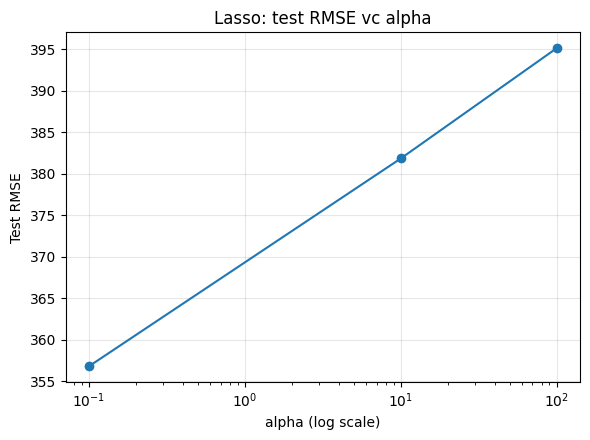

In [7]:
plt.figure(figsize=(6, 4.5))
subset = alpha_table[alpha_table['Model'] == 'Lasso']
plt.semilogx(subset['alpha'], subset['Test RMSE'], marker='o')
plt.title('Lasso: test RMSE vc alpha')
plt.xlabel('alpha (log scale)')
plt.ylabel('Test RMSE')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Questions:
1. Which α produces the lowest test RMSE among the three values?

> *The alpha 0.1 produced the lowest test RMSE (356.83)*

2. Which α appears to cause the most underfitting? Explain using bias.

> *The alpha 100 appears to cause the most underfitting, it is the simpler model with only 5 predictors and have the highest train and test RMSE. This model may have applyed too much penalty and removed important predictor for the prediction causing high bias.*

3. Why might a model with higher training RMSE produce lower test RMSE?

> *For those three models that did not happen; As the training RMSE increases the test RMSE also increase. That might happen if the model is biased and the training model learned so much*

## Part 3 - Model interpretation
Using your results from Part 1:
1. Identify two predictors that Lasso sets to zero at α = 100.

> *num__CHits	and num__CHmRun*

2. Does setting their coefficients to zero prove that these predictors have no relationship
with salary? Explain.

> *No, setting predictor to zero means that Lasso removed correlated coefficients. Those coeffiencient may explain the same thing and have relationship with salary.*

3. If two models have very similar test RMSE but one uses fewer predictors, which would
you prefer? Explain your answer in terms of interpretability and predictive performance

> *It depends. If I wanted more interpretability I would choose the model with fewer features; If I wanted more flexibility I would keep predictor to explain the relationship with the target*

In [8]:
feature_names = pipe.named_steps['preprocess'].get_feature_names_out()

coef_table = pd.DataFrame({
    'Feature': feature_names,
    'Lasso alpha=100': pipe.named_steps['model'].coef_
})

display(coef_table.round(2))

,Feature,Lasso alpha=100
0,num__AtBat,0.00
1,num__Hits,76.59
2,num__HmRun,0.00
3,num__Runs,0.00
4,num__RBI,0.00
5,num__Walks,16.17
6,num__Years,0.00
7,num__CAtBat,0.00
8,num__CHits,0.00
9,num__CHmRun,0.00


In [9]:
predictor_zero = coef_table.loc[coef_table['Lasso alpha=100'].abs() <= 1e-6, 'Feature'].tolist()
print('Zero at alpha = 100:', predictor_zero)

Zero at alpha = 100: ['num__AtBat', 'num__HmRun', 'num__Runs', 'num__RBI', 'num__Years', 'num__CAtBat', 'num__CHits', 'num__CHmRun', 'num__CWalks', 'num__Assists', 'num__Errors', 'cat__League_N', 'cat__Division_W', 'cat__NewLeague_N']


## Part 4 - Choosing the Right Regression Model
For each scenario, choose Ridge (L2), Lasso (L1), Ordinary Linear Regression, or Not Sure.
Explain your choice in 2-3 sentences, considering the number of predictors, model complexity,
interpretability, and potential overfitting.
- Scenario A: A researcher has data from 80 patients with 200 medical measurements. The
goal is to identify a small number of measurements that may be useful for predicting
disease severity.

> *I would choose Lasso (L1), the researcher wants to eliminate measurements and Lasso does that job; It will punish the high weithed features and zero it to predict with fewer measurements as possible.*
    
- Scenario B: A company wants to predict employee salaries using 40 predictors. Many
predictors are strongly correlated, and the company believes most contain useful
information. Keeping all predictors is not a concern.

> *I would choose Ridge (L2), the company wants to keep all the predictors; Ridge will punish higher weights but the correlated features will get shared weight.*  

- Scenario C: A researcher has 10,000 observations and only three predictors. The
relationship appears approximately linear, and the researcher wants a simple model that is
easy to interpret.

> *I would choose Ordinary Linear Regression, this is the simpler model and they already have three predictors. The OLS will look at the difference between the line and the dot not punishment.*

- Scenario D: A company has 500 observations and 25 predictors. It is unclear how many
predictors are useful or how strongly they are correlated. The company wants the most
accurate predictions possible

> *We cannot zero coefficients or share their weight if the company does not have not enough information for the decision.*